In [2]:
from SALib.sample import sobol
from SALib.analyze import sobol
import matplotlib.pyplot as plt
import numpy as np
import re
import pandas as pd
from scipy.interpolate import RBFInterpolator
from SALib.sample import saltelli
from scipy import optimize
from dolfin import *
import matplotlib as mpl
from scipy.optimize import curve_fit
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
from numpy import inf
import matplotlib.patches as mpatches
import csv
import subprocess
import seaborn as sns

In [3]:
headers = ['alpha', 'beta', 'vd', 'sg', 'D']
PDE_names = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D'])['sim_name']
par_mn_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', index_col=0, header=None, names=headers)
par_lb_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', index_col=0, header=None, names=headers)
par_ub_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', index_col=0, header=None, names=headers)

In [4]:
def round_to_multiple(number, multiple):
    return multiple * np.round(number / multiple)

def get_n(s):
    match = re.search(r'\d+$', s)
    if match:
        return int(match.group())
    else:
        return None

In [5]:
def PDE(pars, upar, time, plot):
    '''
    pars = dictionary of parameters to fit (key = parameter name, value = parameter value).
    upar = parameters of initial condition [A, s, r0].
    time = hours.
    plot = whether or not to show plot of PDE solution (1=yes).
    '''
    alphval = pars[0]
    beta = Constant(pars[1])
    v_sval = pars[2]
    s_scal =  Constant(pars[3])
    D = Constant(pars[4])

    # Define the problem
    Length = 3 # 40.0
    left = 1e-3
    dX = 0.01
    X = np.arange(left, Length, dX)
    nx = len(X)
    nT = int(time * 10) # 900
    keep = 10 # get every hour
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    cmap2 = mpl.colormaps["spring"]
    cmap = mpl.colormaps["winter"]
    set_log_level(LogLevel.WARNING)

    density_tip_t = np.zeros((int(nT / keep), nx))
    density_in_t = np.zeros((int(nT / keep), nx))
    n_sat_r = []
    rho_sat_r = []
    x_r = []

    # Define the parameters
    T = time # 90
    dt = T/nT
    # alphval = 0.039
    cval = 0.6
    # Define the initial condition
    u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
    u0 = Expression((u0_str, '0.0'), degree=1)
    #define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    # Define other elements

    u_n = interpolate(u0, V)
    u = Function (V)
    n, rho = split(u)
    n_n, rho_n= split(u_n)
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))

    # s_scal =  Constant(0.0288) # Constant(0.2)
    # beta = Constant(0.022)
    alpha = Constant(alphval)
    # D = Constant(0.02)

    n_mid = 0.5*(n_n + n)
    # v_sval = 0.235
    v_s = Constant((v_sval,))

    F = n * v_1 * dx - n_n * v_1 * dx
    # Diffusion term
    F += D * dot(grad(n), grad(v_1)) * dt * dx
    # Cylindrical correction terms using invr
    F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
    F += dt * dot(grad(n_mid), v_s) * v_1 * dx
    F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

    F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
    F += beta * v_1 * rho * n * dt * dx
    F -= alpha * n * v_1 * dt * dx

    # Apply the boundary conditions (left=left, right=Length)
    u_L = (Constant(0.0), Constant(0.0))
    u_R = (Constant(0.0), Constant(0.0))
    bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]

    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    # X = np.arange(left, Length, dx)
    poss = []

    i=0

    if plot == 1:
        fig, axs = plt.subplots(3, 1)
    for t in np.linspace(0,T,nT):
        try:
            solve(F==0, u,bcs)
            u_n.assign(u)
            _n, _rho= u.split()

            if i%keep==0:# i%100==0:
                n_field = interpolate(_n, V2)
                rho_field = interpolate(_rho, V2)
                density_tip_t[int(i / keep), :] = [n_field(x) for x in X]
                density_in_t[int(i / keep), :] = [rho_field(x) for x in X]
                poss.append(np.argmax([n_field(x) for x in X]))
                if plot == 1:
                    axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                    axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

                    if i > nT / 2:
                        axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))

            xi = np.argmax([n_field(x) for x in X]) * (Length / nx) - upar[2]
            if round(xi, 2) % 0.05 <= 0.02:
                if round_to_multiple(xi, 0.05) not in x_r:
                    rho_nonzero = density_in_t[int(i / keep), :][density_in_t[int(i / keep), :] > 0.1]
                    n_sat_r.append(max([n_field(x) for x in X]))
                    if len(rho_nonzero) > 0:
                        rho_sat_r.append(np.median(rho_nonzero))
                    else:
                        rho_sat_r.append(0)
                    x_r.append(round_to_multiple(xi, 0.05))

        except RuntimeError as e:
            print('hour ' + str(t))
            print(e)
            if i%keep==0:# i%100==0:
                density_tip_t[int(i / keep), :] = np.zeros(len(X))
                density_in_t[int(i / keep), :] = np.zeros(len(X))
                poss.append(0)
        i += 1

    plt.show()

    dxdt = np.array(poss)*Length/nx - upar[2]

    n_sat_t = []
    rho_sat_t = []

    for t in np.arange(T):
        # collect PDE output for each hour
        # saturation density
        n_sat_t.append(np.max(density_tip_t[t, :]))
        rho_nonzero = density_in_t[t, :][density_in_t[t, :] > 0.1]
        if len(rho_nonzero) > 0:
            rho_sat_t.append(np.median(rho_nonzero))
        else:
            rho_sat_t.append(0)
            
        # to_fit_in = density_in[t, :]
        # cs = CubicSpline(X, to_fit_in)

        # for j in range(len(X)):
        #     if cs(X, 1)[j] < 0 and cs(X, 1)[j-1] > 0:
        #         cutoff = j
        #         break
        #     else:
        #         cutoff = 0
        # try:
        #     K_guess = np.max(to_fit_in[cutoff:])
        #     L_guess = np.max(X)
        #     r0_guess = np.median(X[cutoff:])
        #     p0_sig = [K_guess, L_guess, r0_guess] # initial guess 
        #     popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
        #     if popt_sig[0] > np.max(to_fit_in):
        #         rho_sat.append(np.max(to_fit_in))
        #     else:
        #         rho_sat.append(popt_sig[0])
        # except RuntimeError as e:
        #     rho_sat.append(np.max(to_fit_in))
        #     print('hour ' + str(t))
        #     print(e)


    x_r = np.array(list(x_r))

    data_t = pd.DataFrame({'n': np.array(n_sat_t), 'rho': np.array(rho_sat_t), 'c': dxdt, 't': np.arange(T)})
    data_r = pd.DataFrame({'n': np.array(n_sat_r), 'rho': np.array(rho_sat_r), 'r': x_r})

    for r in np.arange(data_r['r'].max() + 0.05, 1.05, 0.05):
        data_r.loc[len(data_r)] = [0, 0, round_to_multiple(r, 0.05)]

    return data_t, data_r

In [6]:
def plot_residual(best, upper, lower, args):
    '''
    best = best parameters of PDE
    upper = upper bound parameters of PDE (use [0, 0, 0, 0, 0] to skip)
    lower = lower bound parameters of PDE
    args = arguments based on simulation ({'z': z, 'time': len(z[0]))
    z = ABM output for each hour except 0 (ABM(['bmx_default0', 'bmx_default1', 'bmx_default2'], 500000, 0.005))
    time = hours (from length of z data)
    '''
    z, time = args['z'], args['time']
    
    upar = [z[7], z[8], z[9]]
    upar[2] = 0.1
    
    t0 = z[10]
    shifted_time = time - t0
    
    z_t, z_r = z[0:2]
    y_t, y_r = PDE(best, upar, time, 0)
 
    r_data = z_r.merge(y_r, on = 'r', how = 'inner', suffixes = ('_z', '_y'))
    r_data['n_res'] = abs(r_data['n_z'] - r_data['n_y'])
    r_data['rho_res'] = abs(r_data['rho_z'] - r_data['rho_y'])
    r_data['n_wssr'] = (r_data['n_wt'] * r_data['n_res']) ** 2
    r_data['rho_wssr'] = (r_data['rho_wt'] * r_data['rho_res']) ** 2

    t_data = z_t.merge(y_t, on = 't', how = 'inner', suffixes = ('_z', '_y'))
    t_data['n_res'] = abs(t_data['n_z'] - t_data['n_y'])
    t_data['rho_res'] = abs(t_data['rho_z'] - t_data['rho_y'])
    t_data['n_wssr'] = (t_data['n_wt'] * t_data['n_res']) ** 2
    t_data['rho_wssr'] = (t_data['rho_wt'] * t_data['rho_res']) ** 2
    t_data['c_res'] = abs(t_data['c_z'] - t_data['c_y'])
    t_data['c_wssr'] = (t_data['c_wt'] * t_data['c_res']) ** 2

    rmse_n_t = np.sqrt(((t_data['n_res'] ** 2).sum()) / len(t_data['n_res'])) / (t_data['n_z'].max() - t_data['n_z'].min())
    rmse_rho_t = np.sqrt(((t_data['rho_res'] ** 2).sum()) / len(t_data['rho_res'])) / (t_data['rho_z'].max() - t_data['rho_z'].min())
    rmse_c_t = np.sqrt(((t_data['c_res'] ** 2).sum()) / len(t_data['c_res'])) / (t_data['c_z'].max() - t_data['c_z'].min())
    rmse_n_r = np.sqrt(((r_data['n_res'] ** 2).sum()) / len(r_data['n_res'])) / (r_data['n_z'].max() - r_data['n_z'].min())
    rmse_rho_r = np.sqrt(((r_data['rho_res'] ** 2).sum()) / len(r_data['rho_res'])) / (r_data['rho_z'].max() - r_data['rho_z'].min())


    if upper[0] != 0:
        y_t_lower, y_r_lower = PDE(lower, upar, time, 0)
        y_t_upper, y_r_upper = PDE(upper, upar, time, 0)
        y_t_uncertainty = y_t.merge(y_t_lower, on = 't', how = 'inner', suffixes = (None, '_lower'))
        y_t_uncertainty = y_t_uncertainty.merge(y_t_upper, on = 't', how = 'inner', suffixes = (None, '_upper'))
        y_r_uncertainty = y_r.merge(y_r_lower, on = 'r', how = 'inner', suffixes = (None, '_lower'))
        y_r_uncertainty = y_r_uncertainty.merge(y_r_upper, on = 'r', how = 'inner', suffixes = (None, '_upper'))

        fig, axs = plt.subplots(3, 1, figsize = (3, 8))
        # subfigs = fig.subfigures(1, 5) 
        ABM_line = axs[0].plot(t_data['t'], t_data['n_z'], color = 'y', label = 'ABM')
        PDE_line = axs[0].plot(t_data['t'], t_data['n_y'], color ='tomato', label = 'PDE best fit')
        ABM_fill = axs[0].fill_between(t_data['t'], t_data['n_z'] - t_data['n_std'], t_data['n_z'] + t_data['n_std'], alpha = 0.3, color = 'y', label = 'ABM')
        # axs[0].set_title(f'Maximum tip density: RMSE={rmse_n_t:.2f}')
        axs[1].plot(t_data['t'], t_data['rho_z'], color = 'y')
        axs[1].plot(t_data['t'], t_data['rho_y'], color ='tomato')
        axs[1].fill_between(t_data['t'], t_data['rho_z'] - t_data['rho_std'], t_data['rho_z'] + t_data['rho_std'], alpha = 0.3, color = 'y')
        # axs[1].set_title(f'Median filament density: RMSE={rmse_rho_t:.2f}')
        axs[2].plot(t_data['t'], t_data['c_z'], color = 'y')
        axs[2].plot(t_data['t'], t_data['c_y'], color ='tomato')
        axs[2].fill_between(t_data['t'], t_data['c_z'] - t_data['c_std'], t_data['c_z'] + t_data['c_std'], alpha = 0.3, color = 'y')
        # axs[2].set_title(f'Wave speed: RMSE={rmse_c_t:.2f}')
        # axs[3].plot(r_data['r'], r_data['n_z'], color = 'y')
        # axs[3].plot(r_data['r'], r_data['n_y'], color ='r')
        # axs[3].fill_between(r_data['r'], r_data['n_z'] - r_data['n_std'], r_data['n_z'] + r_data['n_std'], alpha = 0.3, color = 'y')
        # axs[3].set_title(f'Median tip density: RMSE={rmse_n_r:.2f}')
        # axs[3].set_xlabel('radius(mm)')
        # axs[4].plot(r_data['r'], r_data['rho_z'], color = 'y')
        # axs[4].plot(r_data['r'], r_data['rho_y'], color ='r')
        # axs[4].fill_between(r_data['r'], r_data['rho_z'] - r_data['rho_std'], r_data['rho_z'] + r_data['rho_std'], alpha = 0.3, color = 'y')
        # axs[4].set_title(f'Median filament density: RMSE={rmse_rho_r:.2f}')
        PDE_dash = axs[0].plot(y_t_uncertainty['t'], y_t_uncertainty['n_lower'], color = 'tomato', linestyle = '--', label = 'PDE 95% confidence bounds')
        axs[0].plot(y_t_uncertainty['t'], y_t_uncertainty['n_upper'], color = 'tomato', linestyle = '--')
        axs[1].plot(y_t_uncertainty['t'], y_t_uncertainty['rho_lower'], color = 'tomato', linestyle = '--')
        axs[1].plot(y_t_uncertainty['t'], y_t_uncertainty['rho_upper'], color = 'tomato', linestyle = '--')
        axs[2].plot(y_t_uncertainty['t'], y_t_uncertainty['c_lower'], color = 'tomato', linestyle = '--')
        axs[2].plot(y_t_uncertainty['t'], y_t_uncertainty['c_upper'], color = 'tomato', linestyle = '--')
        # axs[3].plot(y_r_uncertainty['r'],y_r_uncertainty['n_lower'], 'r--')
        # axs[3].plot(y_r_uncertainty['r'],y_r_uncertainty['n_upper'], 'r--')
        # axs[4].plot(y_r_uncertainty['r'], y_r_uncertainty['rho_lower'], 'r--')
        # axs[4].plot(y_r_uncertainty['r'], y_r_uncertainty['rho_upper'], 'r--')
        # axs[0].set_xlabel('time(hrs)')
        axs[0].set_ylabel(r'$n(mm^{-2})$')
        # axs[1].set_xlabel('time(hrs)')
        axs[1].set_ylabel(r'$\rho(mmmm^{-2})$')
        axs[2].set_xlabel(r'$time(hrs)$')
        axs[2].set_ylabel(r'$position(mm)$')
        ABM_patch = mpatches.Patch(color=ABM_fill.get_facecolor(), alpha=0.3)
        axs[0].legend(handles=[(ABM_line[0], ABM_patch), PDE_line[0], PDE_dash[0]], 
                      labels=['ABM', 'PDE best fit', 'PDE 95% confidence bounds'], 
                      handleheight=2)
        # axs[3].set_xlabel(r'$density(mm^{-2})$')
        # axs[3].set_ylabel(r'$density(mm^{-2})$')
        # axs[4].set_xlabel('radius(mm)')
        # axs[4].set_ylabel(r'$density(mmmm^{-2})$')
        # fig.suptitle('Simulation (green) and PDE (red) output for the three parameterization objectives.')
    else:
        fig, axs = plt.subplots(3, 1, figsize = (3, 8))
        # subfigs = fig.subfigures(1, 5) 
        ABM_line = axs[0].plot(t_data['t'], t_data['n_z'], color = 'y', label = 'ABM')
        PDE_line = axs[0].plot(t_data['t'], t_data['n_y'], color ='tomato', label = 'PDE best fit')
        ABM_fill = axs[0].fill_between(t_data['t'], t_data['n_z'] - t_data['n_std'], t_data['n_z'] + t_data['n_std'], alpha = 0.3, color = 'y', label = 'ABM')
        # axs[0].set_title(f'Maximum tip density: RMSE={rmse_n_t:.2f}')
        axs[1].plot(t_data['t'], t_data['rho_z'], color = 'y')
        axs[1].plot(t_data['t'], t_data['rho_y'], color ='tomato')
        axs[1].fill_between(t_data['t'], t_data['rho_z'] - t_data['rho_std'], t_data['rho_z'] + t_data['rho_std'], alpha = 0.3, color = 'y')
        # axs[1].set_title(f'Median filament density: RMSE={rmse_rho_t:.2f}')
        axs[2].plot(t_data['t'], t_data['c_z'], color = 'y')
        axs[2].plot(t_data['t'], t_data['c_y'], color ='tomato')
        axs[2].fill_between(t_data['t'], t_data['c_z'] - t_data['c_std'], t_data['c_z'] + t_data['c_std'], alpha = 0.3, color = 'y')
        axs[0].set_ylabel(r'$n(mm^{-2})$')
        # axs[1].set_xlabel('time(hrs)')
        axs[1].set_ylabel(r'$\rho(mmmm^{-2})$')
        axs[2].set_xlabel(r'$time(hrs)$')
        axs[2].set_ylabel(r'$position(mm)$')
        ABM_patch = mpatches.Patch(color=ABM_fill.get_facecolor(), alpha=0.3)
        axs[0].legend(handles=[(ABM_line[0], ABM_patch), PDE_line[0]], 
                      labels=['ABM', 'PDE best fit'], 
                      handleheight=2)
    plt.tight_layout()
    # plt.close()
    plt.show()
    return fig

In [7]:
def fit_dis(par_dis, alpha, sim_name):
    '''
    par_dis = list of pareto distributions for each parameter and the calculated number of bins for the histogram [[distribution1, nbins1], ...].
    alpha = alpha for ks test fitting distributions.
    sim_name = name of simulation for labeling output file.
    '''
    par_names = [r'$\alpha$', r'$\beta$', r'$v_d$', r'$s_g$', r'$D$']
    par_units = [r'$hr^{-1}$', r'$mmhr^{-1}$', r'$mmhr^{-1}$', r'$mmhr^{-1}$', r'$mm^{2}hr^{-1}$']
    lower = []
    upper = []
    d = len(par_dis)
    fig, ax = plt.subplots(1,d, figsize = (2.3 * d, 2.3))
    for i in range(d):
        pd = par_dis[i]
        data = pd[0]
        bins = pd[1]
        pval_best = 0
        common_dis = [stats.lognorm,  stats.chi2, stats.gamma, stats.uniform, stats.expon, stats.pareto, stats.weibull_min, stats.rayleigh]
        for cd in common_dis:
            # fitting each common distribution
            par_guess = cd.fit(data)
            ks_stat, pval = stats.kstest(data, cd.cdf, args = par_guess)
            if pval > pval_best:
                # saving best fit distribution
                pval_best = pval
                dis_best = cd
                par_best = par_guess
        x = np.linspace(min(data), max(data), 1000)
        pdf_best = dis_best.pdf(x, *par_best)
    
        lower.append(dis_best.ppf(alpha / 2, *par_best))
        upper.append(dis_best.ppf(1 - alpha / 2, *par_best))
        
        n, bins, patches = ax[i].hist(data, bins, facecolor = 'xkcd:light periwinkle')
        ax[i].plot(np.linspace(lower[i], upper[i], 1000), pdf_best * np.sum(np.diff(bins) * n), color = 'xkcd:light indigo')
        # ax[i].vlines(lower[i], 0, y_hist.mean(), linestyle = '--', color = 'r')
        # ax[i].vlines(upper[i], 0, y_hist.mean(), linestyle = '--', color = 'r', label = "95% confidence bounds")
        # ax[i].set_title(par_names[i] + ' distribution')
        ax[i].set_xlabel(par_names[i] + '(' + par_units[i] + ')')
        fig.suptitle('Pareto front population')
        # plt.ticklabel_format(axis='x', style='sci', scilimits=(0,0))
        # plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
        # plt.legend()
    ax[0].set_ylabel('frequency')
    fig.tight_layout()
    # plt.savefig(sim_name + '_parameter_distributions.png')
    # plt.show()
    return fig

In [7]:
n = 106
mn_n = par_mn_df.loc['output_fungi_' + str(n)]
lb_n = par_lb_df.loc['output_fungi_' + str(n)]
ub_n = par_ub_df.loc['output_fungi_' + str(n)]

In [8]:
par_mn = [mn_n['alpha'], mn_n['beta'], mn_n['vd'], mn_n['sg'], mn_n['D']]
par_lb = [lb_n['alpha'], lb_n['beta'], lb_n['vd'], lb_n['sg'], lb_n['D']]
par_ub = [ub_n['alpha'], ub_n['beta'], ub_n['vd'], ub_n['sg'], ub_n['D']]

In [9]:
sim_name = 'output_fungi_' + str(n)
z_t = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_tobjectives.csv')
z_r = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_robjectives.csv')
z_const = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_constantguess.csv')
z = [z_t, z_r, z_const['alpha'][0], z_const['beta'][0], z_const['vd'][0], z_const['sg'][0], z_const['D'][0], z_const['A'][0], z_const['s'][0], z_const['r0'][0], z_const['t0'][0]]

Form has no parts with arity 2.
Form has no parts with arity 2.
Form has no parts with arity 2.


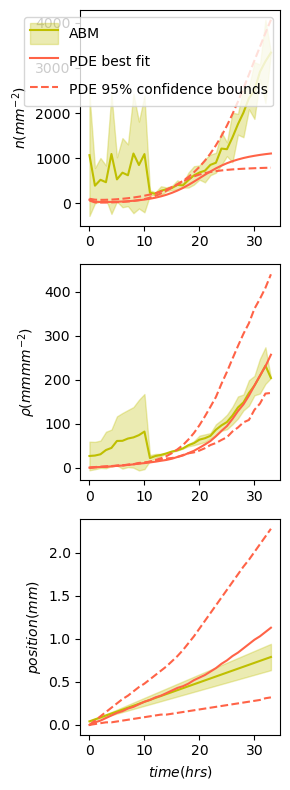

In [10]:
uncb_unc = plot_residual(par_mn, par_ub, par_lb, {'z': z, 'time': len(z[0])})
# uncb_unc.savefig('residuals_ex.svg')

In [13]:
sim_name = 'output_fungi_24'
X = np.loadtxt('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_X', delimiter=',')

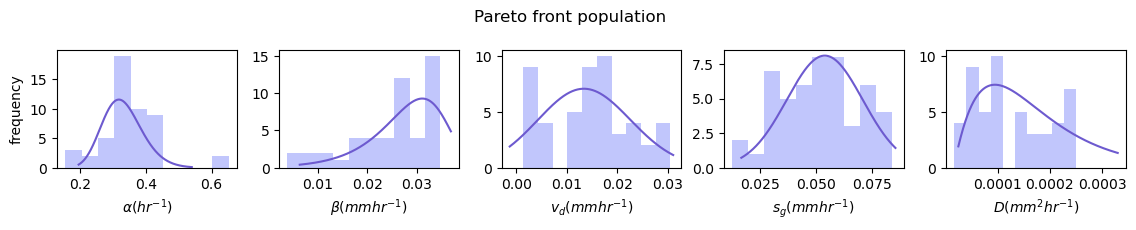

In [14]:
par_dis = []
for i in range(5):
    data = X[:, i]
    par_dis.append([data, int(np.sqrt(int(len(data))) * 1.5)])
par_hist = fit_dis(par_dis, 0.05, sim_name)
par_hist.savefig('par_distribution_ex.svg')

In [11]:
def goodness_of_fit(best, args):
    z, time = args['z'], args['time']
    
    upar = [z[7], z[8], z[9]]
    upar[2] = 0.1
    
    t0 = z[10]
    shifted_time = time - t0
    
    z_t, z_r = z[0:2]
    y_t, y_r = PDE(best, upar, time, 0)

    t_data = z_t.merge(y_t, on = 't', how = 'inner', suffixes = ('_z', '_y'))
    t_data['n_res'] = abs(t_data['n_z'] - t_data['n_y'])
    t_data['rho_res'] = abs(t_data['rho_z'] - t_data['rho_y'])
    t_data['n_wssr'] = t_data['n_wt'] * (t_data['n_res'] ** 2)
    t_data['rho_wssr'] = t_data['rho_wt'] * (t_data['rho_res'] ** 2)
    t_data['c_res'] = abs(t_data['c_z'] - t_data['c_y'])
    t_data['c_wssr'] = t_data['c_wt'] * (t_data['c_res'] ** 2)
    t_data['n_tss'] = abs(t_data['n_z'] - t_data['n_z'].mean()) ** 2
    t_data['rho_tss'] = abs(t_data['rho_z'] - t_data['rho_z'].mean()) ** 2
    t_data['c_tss'] = abs(t_data['c_z'] - t_data['c_z'].mean()) ** 2

    t_data = t_data.dropna()
    p = 5
    N = len(t_data)

    chi2_n_t = t_data['n_wssr'].sum() / (N - p) / (t_data['n_z'].max() - t_data['n_z'].min())
    chi2_rho_t = t_data['rho_wssr'].sum() / (N - p) / (t_data['rho_z'].max() - t_data['rho_z'].min())
    chi2_c_t = t_data['c_wssr'].sum() / (N - p) / (t_data['c_z'].max() - t_data['c_z'].min())

    l2_n_t = np.sqrt(((t_data['n_res'] ** 2).sum()) / len(t_data['n_res'])) / np.sqrt(((t_data['n_z'] ** 2).sum()) / len(t_data['n_z']))
    l2_rho_t = np.sqrt(((t_data['rho_res'] ** 2).sum()) / len(t_data['rho_res'])) / np.sqrt(((t_data['rho_z'] ** 2).sum()) / len(t_data['rho_z']))
    l2_c_t = np.sqrt(((t_data['c_res'] ** 2).sum()) / len(t_data['c_res'])) / np.sqrt(((t_data['c_z'] ** 2).sum()) / len(t_data['c_z']))

    r2_n_t = 1 - ((t_data['n_res'] ** 2).sum() / t_data['n_tss'].sum())
    r2_rho_t = 1 - ((t_data['rho_res'] ** 2).sum() / t_data['rho_tss'].sum())
    r2_c_t = 1 - ((t_data['c_res'] ** 2).sum() / t_data['c_tss'].sum())

    wr2_n_t = 1 - (t_data['n_wssr'].sum() / t_data['n_tss'].sum())
    wr2_rho_t = 1 - (t_data['rho_wssr'].sum() / t_data['rho_tss'].sum())
    wr2_c_t = 1 - ((t_data['c_res'] ** 2).sum() / t_data['c_tss'].sum())

    rmse_n_t = np.sqrt(((t_data['n_res'] ** 2).sum()) / len(t_data['n_res'])) / (t_data['n_z'].max() - t_data['n_z'].min())
    rmse_rho_t = np.sqrt(((t_data['rho_res'] ** 2).sum()) / len(t_data['rho_res'])) / (t_data['rho_z'].max() - t_data['rho_z'].min())
    rmse_c_t = np.sqrt(((t_data['c_res'] ** 2).sum()) / len(t_data['c_res'])) / (t_data['c_z'].max() - t_data['c_z'].min())

    return [[rmse_n_t, rmse_rho_t, rmse_c_t], [chi2_n_t, chi2_rho_t, chi2_c_t], [r2_n_t, r2_rho_t, r2_c_t], [wr2_n_t, wr2_rho_t, wr2_c_t], [l2_n_t, l2_rho_t, l2_c_t]]

In [16]:
rmse_n = []
rmse_rho = []
rmse_c = []
chi2_n = []
chi2_rho = []
chi2_c = []
r2_n = []
r2_rho = []
r2_c = []
wr2_n = []
wr2_rho = []
wr2_c = []
l2_n = []
l2_rho = []
l2_c = []
use_par0 = []

sim_names = PDE_names.to_list()
for sim in sim_names:
    n = get_n(sim)
    mn_n = par_mn_df.loc['output_fungi_' + str(n)]
    lb_n = par_lb_df.loc['output_fungi_' + str(n)]
    ub_n = par_ub_df.loc['output_fungi_' + str(n)]
    par0 = [z[2], z[3], z[4], z[5], z[6]]
    par_mn = [mn_n['alpha'], mn_n['beta'], mn_n['vd'], mn_n['sg'], mn_n['D']]
    par_ub = [ub_n['alpha'], ub_n['beta'], ub_n['vd'], ub_n['sg'], ub_n['D']]
    par_lb = [lb_n['alpha'], lb_n['beta'], lb_n['vd'], lb_n['sg'], lb_n['D']]
    
    sim_name = 'output_fungi_' + str(n)
    z_t = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_tobjectives.csv')
    z_r = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_robjectives.csv')
    z_const = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_constantguess.csv')
    z = [z_t, z_r, z_const['alpha'][0], z_const['beta'][0], z_const['vd'][0], z_const['sg'][0], z_const['D'][0], z_const['A'][0], z_const['s'][0], z_const['r0'][0], z_const['t0'][0]]

    rmse, chi2, r2, wr2, l2 = goodness_of_fit(par_mn, {'z': z, 'time': len(z[0])})
    # rmse0, chi20, r20, wr20, l20 = goodness_of_fit(par0, {'z': z, 'time': len(z[0])})

    # if sum(rmse) > sum(rmse0):
    #     use_par0.append(n)
    #     print('Using initial guess:' + str(n))
    #     rmse_n.append(rmse0[0])
    #     rmse_rho.append(rmse0[1])
    #     rmse_c.append(rmse0[2])
    #     a = plot_residual(np.array(par0), [0,0,0,0,0], [0,0,0,0,0], {'z': z, 'time': len(z[0])})
    #     a.savefig(str(n) + '_best_residuals.png')
    #     with open('par_best.csv', 'a') as f:
    #         writer = csv.writer(f)
    #         writer.writerow([sim_name] + par0 + ['guess'])
    #         f.close()
    # else:
    rmse_n.append(rmse[0])
    rmse_rho.append(rmse[1])
    rmse_c.append(rmse[2])
        # a = plot_residual(np.array(par_mn), par_ub, par_lb, {'z': z, 'time': len(z[0])})
        # a.savefig(str(n) + '_best_residuals.png')
        # with open('par_best.csv', 'a') as f:
        #     writer = csv.writer(f)
        #     writer.writerow([sim_name] + par_mn + ['pareto'])
        #     f.close()
    
    chi2_n.append(chi2[0])
    chi2_rho.append(chi2[1])
    chi2_c.append(chi2[2])
    r2_n.append(r2[0])
    r2_rho.append(r2[1])
    r2_c.append(r2[2])
    wr2_n.append(wr2[0])
    wr2_rho.append(wr2[1])
    wr2_c.append(wr2[2])
    l2_n.append(l2[0])
    l2_rho.append(l2[1])
    l2_c.append(l2[2])

Form has no parts with arity 2.
Form has no parts with arity 2.
Form has no parts with arity 2.


KeyboardInterrupt: 

In [ ]:
from matplotlib.ticker import LogFormatterSciNotation
par_dis = [rmse_n, rmse_rho, rmse_c]
par_names = [r'$n$', r'$\rho$', r'$c$']
d = 3
bns = 15
fig, ax = plt.subplots(1,d, figsize = (4 * d, 4), sharey = 'row')
for i, data in enumerate(par_dis):
    data = par_dis[i]
    logbins = np.geomspace(min(data), max(data), bns+1)
    ax[i].hist(data, facecolor = 'xkcd:teal blue', bins = logbins)
    ax[i].hist(data, facecolor = 'None', edgecolor = 'xkcd:prussian blue', bins = logbins)
    ax[i].set_xscale('log')
    ax[i].set_title(par_names[i])
    ax[i].text(1e-1, 35, 'mean=' + str(np.mean(data)))

fig.supxlabel(r'$RMSE$')
ax[0].set_ylabel('frequency')
fig.tight_layout()

In [18]:
# from matplotlib.ticker import LogFormatterSciNotation
# par_dis = [chi2_n, chi2_rho, chi2_c]
# par_names = [r'$n$', r'$\rho$', r'$c$']
# d = 3
# bns = 15
# fig, ax = plt.subplots(1,d, figsize = (4 * d, 4), sharey = 'row')
# for i, data in enumerate(par_dis):
#     data = par_dis[i]
#     logbins = np.geomspace(min(data), max(data), bns+1)
#     ax[i].hist(data, facecolor = 'xkcd:teal blue', bins = logbins)
#     ax[i].hist(data, facecolor = 'None', edgecolor = 'xkcd:prussian blue', bins = logbins)
#     ax[i].set_xscale('log')
#     ax[i].set_title(par_names[i])

# fig.supxlabel(r'$\chi^2$')
# ax[0].set_ylabel('frequency')
# fig.tight_layout()

In [19]:
# from matplotlib.ticker import LogFormatterSciNotation
# par_dis = [r2_n, r2_rho, r2_c]
# par_names = [r'$n$', r'$\rho$', r'$c$']
# d = 3
# bns = 15
# fig, ax = plt.subplots(1,d, figsize = (4 * d, 4), sharey = 'row')
# for i, data in enumerate(par_dis):
#     data = np.array(par_dis[i])
#     ax[i].hist(data, facecolor = 'xkcd:teal blue', bins = bns)
#     ax[i].hist(data, facecolor = 'None', edgecolor = 'xkcd:prussian blue', bins = bns)
#     ax[i].set_title(par_names[i])

# fig.supxlabel(r'$r^2$')
# ax[0].set_ylabel('frequency')
# fig.tight_layout()

In [20]:
# from matplotlib.ticker import LogFormatterSciNotation
# par_dis = [wr2_n, wr2_rho, wr2_c]
# par_names = [r'$n$', r'$\rho$', r'$c$']
# d = 3
# bns = 15
# fig, ax = plt.subplots(1,d, figsize = (4 * d, 4), sharey = 'row')
# for i, data in enumerate(par_dis):
#     data = np.array(par_dis[i])
#     ax[i].hist(data, facecolor = 'xkcd:teal blue', bins = bns)
#     ax[i].hist(data, facecolor = 'None', edgecolor = 'xkcd:prussian blue', bins = bns)
#     ax[i].set_title(par_names[i])

# fig.supxlabel(r'$r^2_{weighted}$')
# ax[0].set_ylabel('frequency')
# fig.tight_layout()

In [21]:
# from matplotlib.ticker import LogFormatterSciNotation
# par_dis = [l2_n, l2_rho, l2_c]
# par_names = [r'$n$', r'$\rho$', r'$c$']
# d = 3
# bns = 15
# fig, ax = plt.subplots(1,d, figsize = (4 * d, 4), sharey = 'row')
# for i, data in enumerate(par_dis):
#     data = par_dis[i]
#     logbins = np.geomspace(min(data), max(data), bns+1)
#     ax[i].hist(data, facecolor = 'xkcd:teal blue', bins = logbins)
#     ax[i].hist(data, facecolor = 'None', edgecolor = 'xkcd:prussian blue', bins = logbins)
#     ax[i].set_xscale('log')
#     ax[i].set_title(par_names[i])

# fig.supxlabel(r'$l^2$')
# ax[0].set_ylabel('frequency')
# fig.tight_layout()

In [ ]:
# fig, ax = plt.subplots(1, 3, figsize = (17, 5))
# bns = 20
# logbins = np.geomspace(min(rmse_n), max(rmse_n), bns+1)
# ax[0].hist(rmse_n, bins = logbins)
# logbins = np.geomspace(min(rmse_rho), max(rmse_rho), bns+1)
# ax[1].hist(rmse_rho, bins = logbins)
# logbins = np.geomspace(min(rmse_c), max(rmse_c), bns+1)
# ax[2].hist(rmse_c, bins = logbins)
# ax[0].set_xscale('log')
# ax[1].set_xscale('log')
# ax[2].set_xscale('log')

In [ ]:
    # if (np.array(X2) > 500).any():
    #     par_mn = [z[2], z[3], z[4], z[5], z[6]]
    #     X2 = x2(par_mn, {'z': z, 'time': len(z[0])})
    # if (np.array(L2) > 10).any():
    #     par_mn = [z[2], z[3], z[4], z[5], z[6]]
    #     L2 = l2(par_mn, {'z': z, 'time': len(z[0])})

    # X2_n.append(X2[0])
    # X2_rho.append(X2[1])
    # X2_c.append(X2[2])
    # L2_n.append(L2[0])
    # L2_rho.append(L2[1])
    # L2_c.append(L2[2])

In [8]:
sim_names = PDE_names.to_list()
nlist = []
for sim in sim_names:
    n = get_n(sim)
    print(n, end=" ")

104 131 105 132 133 106 134 117 137 118 138 145 120 128 146 147 129 148 140 121 141 149 122 142 144 126 127 13 123 14 115 10 119 0 15 17 150 152 18 153 101 154 109 158 108 159 112 160 113 114 162 163 166 167 200 192 201 193 195 205 197 206 198 207 210 170 211 171 174 213 215 176 216 177 219 180 181 242 222 244 224 245 227 246 248 228 250 252 229 26 230 233 235 237 238 241 100 179 19 184 185 21 22 188 23 189 24 203 25 218 221 240 32 37 38 33 34 39 40 42 43 45 46 48 4 50 51 54 59 60 65 66 69 6 72 76 78 107 3 71 75 80 82 83 84 86 88 89 8 92 93 94 9 41 74 182 249 254 

In [9]:
# alpha_r2 = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/alpha_r2.csv', header = None, names = ['run', 'alpha_r2'])
# beta_r2 = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/beta_r2.csv', header = None, names = ['run', 'beta_r2'])
# alpha_beta_r2 = alpha_r2.merge(beta_r2, on = 'run')

In [10]:
# beta_r2[beta_r2['beta_r2'] == beta_r2['beta_r2'].min()]

In [11]:
# alpha_beta_r2.boxplot(['alpha_r2','beta_r2'], showfliers=False)
# plt.savefig('alpha_r2.svg')

In [12]:
# beta_r2.boxplot(showfliers=False)
# plt.savefig('beta_r2.svg')

In [13]:
speed = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/speed.csv', header =  None, names = ['run', 'c_mean', 'c_std', 'c_intercept', 'tip_mean', 'tip_std', 'tip_intercept', 'in_mean', 'in_std', 'in_intercept'])

In [14]:
speed['c/vpull'] = speed['c_mean'] / speed['tip_mean']
speed['c/vavg'] = speed['c_mean'] / speed['in_mean']

<Axes: >

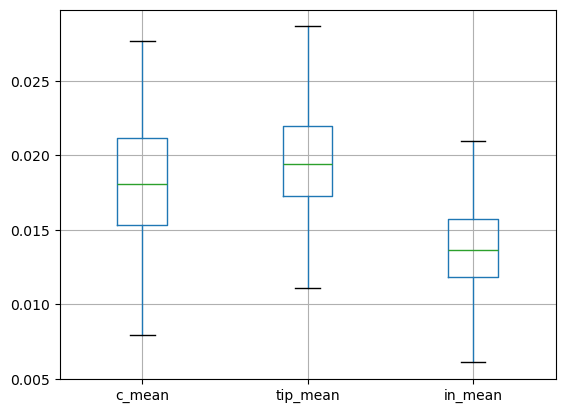

In [19]:
speed.boxplot(['c_mean', 'tip_mean', 'in_mean'], showfliers = False)
# plt.savefig('c.svg')

In [ ]:
speed.boxplot(['c/vpull', 'c/vavg'], showfliers = False)
plt.savefig('c_ratio.svg')

In [15]:
headers = ['run', 'alpha', 'beta', 'vd', 'sg', 'D']
par_mn = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)
par_lb = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', header=None, names=headers)
par_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)
par_mn['rhosat_mn'] = 2 * par_mn['alpha'] / par_mn['beta']

In [16]:
headers = ['run', 'alpha', 'beta', 'vd', 'sg', 'D', 'type']
par_best = pd.read_csv('par_best.csv', header=None, names = headers)
par_best['rho_sat_pred'] = 2 * par_best['alpha'] / par_best['beta']

In [17]:
par_redo = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean_redo.csv', header = None, names = headers)

In [18]:
n = 134
alpha_n = par_redo.loc[par_redo['run'] == 'output_fungi_' + str(n), 'alpha'][0]
beta_n = par_redo.loc[par_redo['run'] == 'output_fungi_' + str(n), 'beta'][0]
vd_n = par_redo.loc[par_redo['run'] == 'output_fungi_' + str(n), 'vd'][0]
sg_n = par_redo.loc[par_redo['run'] == 'output_fungi_' + str(n), 'sg'][0]
D_n = par_redo.loc[par_redo['run'] == 'output_fungi_' + str(n), 'D'][0]
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'alpha'] = alpha_n
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'beta'] = beta_n
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'vd'] = vd_n
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'sg'] = sg_n
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'D'] = D_n
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'type'] = 'redo'
par_best.loc[par_best['run'] == 'output_fungi_' + str(n), 'rho_sat_pred'] = 2 * alpha_n / beta_n

In [19]:
par_best[par_best['run'] == 'output_fungi_' + str(n)]

,run,alpha,beta,vd,sg,D,type,rho_sat_pred
6,output_fungi_134,0.171517,0.000522,0.016222,0.053348,0.00001,redo,657.448409


In [20]:
rho_max = []
rho_var = []
rho_diff = []
n_mean = []
n_var = []
par_guess_list = []
sim_names = PDE_names.to_list()[:153]
for sim in sim_names:
    n = get_n(sim)
    sim_name = 'output_fungi_' + str(n)
    z_t = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_tobjectives.csv')
    rho_max.append(z_t['rho'].max())
    rho_var.append(z_t['rho'].var())
    n_mean.append(z_t['n'].mean())
    n_var.append(z_t['n'].var())
    rho_diff.append(abs(z_t['rho'].iloc[-1] - z_t['rho'].iloc[0]))

    z_const = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_constantguess.csv')
    par_guess_list.append({'run': sim, 'alpha_guess':z_const['alpha'][0], 'beta_guess':z_const['beta'][0], 'vd_guess':z_const['vd'][0], 'sg_guess':z_const['sg'][0], 'D_guess':z_const['D'][0]})

In [21]:
par_guess = pd.DataFrame(par_guess_list)
par_guess['rho_sat_guess'] = 2 * par_guess['alpha_guess'] / par_guess['beta_guess']

In [93]:
par_mn

,run,alpha,beta,vd,sg,D,rhosat_mn
0,output_fungi_104,0.193876,0.006643,0.011279,0.059516,0.000182,58.367777
1,output_fungi_131,0.178985,0.000938,0.005930,0.083790,0.000077,381.621753
2,output_fungi_105,0.239194,0.013272,0.015058,0.073960,0.000166,36.044930
3,output_fungi_132,0.360452,0.052221,0.024576,0.096120,0.000051,13.804747
4,output_fungi_133,0.410329,0.042846,0.029366,0.102816,0.000052,19.153860
...,...,...,...,...,...,...,...
153,output_fungi_41,0.373206,0.023138,0.016663,0.084590,0.000129,32.258900
154,output_fungi_74,0.364894,0.008086,0.002487,0.107249,0.000303,90.249509
155,output_fungi_182,0.233616,0.002312,0.012666,0.098582,0.000307,202.094716
156,output_fungi_249,0.474658,0.018382,0.013776,0.095503,0.000194,51.644711


In [22]:
par_guess

,run,alpha_guess,beta_guess,vd_guess,sg_guess,D_guess,rho_sat_guess
0,output_fungi_104,0.108462,0.002386,0.011400,0.020403,0.000072,90.917536
1,output_fungi_131,0.159848,0.000398,0.011460,0.024735,0.000131,803.864069
2,output_fungi_105,0.106134,0.003249,0.017058,0.023246,0.000223,65.339064
3,output_fungi_132,0.115153,0.015614,0.012540,0.022832,0.000187,14.750043
4,output_fungi_133,0.161668,0.009820,0.015575,0.033402,0.000275,32.926079
...,...,...,...,...,...,...,...
148,output_fungi_8,0.068319,0.002282,0.016728,0.025075,0.000096,59.867231
149,output_fungi_92,0.090488,0.001444,0.012935,0.019349,0.000035,125.339538
150,output_fungi_93,0.147850,0.011004,0.016997,0.033129,0.000153,26.872320
151,output_fungi_94,0.146334,0.001109,0.013045,0.024135,0.000086,263.811656


In [100]:
rho_sat = pd.DataFrame({'run': sim_names, 'rho_sat_data': rho_max, 'rho_sat_var': rho_var, 'diff': rho_diff})
rho_sat = rho_sat.merge(par_mn[['run', 'rhosat_mn']], on = 'run')
rho_sat = rho_sat.merge(par_guess[['run', 'rho_sat_guess']], on = 'run')
rho_sat['ratio'] = rho_sat['rhosat_mn'] / rho_sat['rho_sat_data']
rho_sat = rho_sat.rename(columns={'rhosat_mn':'rho_sat_pred'})
n = pd.DataFrame({'run': sim_names, 'n_data': n_mean, 'n_var': n_var})

In [24]:
rho_sat_bad = rho_sat[rho_sat['rho_sat_pred'] > (10 * rho_sat['rho_sat_data'])]
rho_sat_good = rho_sat[rho_sat['rho_sat_pred'] < (10 * rho_sat['rho_sat_data'])]

In [26]:
rho_sat.boxplot(['rho_sat_data', 'rho_sat_pred', 'rho_sat_guess'], showfliers = False)
# plt.savefig('rho_sat.svg')

<Axes: >

In [172]:
df = rho_sat
col = 'rho_sat_data'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

data_clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)][['rho_sat_data', 'run']]
data_clean['type'] = 'data'
data_clean = data_clean.rename(columns={'rho_sat_data': 'rho_sat'})

col = 'rho_sat_pred'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

pred_clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)][['rho_sat_pred', 'run']]
pred_clean['type'] = 'pred'
pred_clean = pred_clean.rename(columns={'rho_sat_pred': 'rho_sat'})

col = 'rho_sat_guess'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

guess_clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)][['rho_sat_guess', 'run']]
guess_clean['type'] = 'guess'
guess_clean = guess_clean.rename(columns={'rho_sat_guess': 'rho_sat'})

rho_sat_clean = pd.concat([data_clean, pred_clean, guess_clean])
rho_sat_clean['n'] = pd.to_numeric(rho_sat_clean['run'].str.extract(r'(\d+)')[0])
rho_sat_clean['rho_sat_avg'] = rho_sat_clean.groupby(['n'])['rho_sat'].transform('mean')
rho_sat_clean2 = pd.merge(data_clean, pred_clean, on = 'run', how = 'inner', suffixes=('_data', '_pred'))
rho_sat_clean2 = pd.merge(rho_sat_clean2, guess_clean, on = 'run', how = 'inner')
rho_sat_clean2 = rho_sat_clean2.rename(columns={'rho_sat': 'rho_sat_guess'})
rho_sat_clean2 = rho_sat_clean2.drop(['type_data', 'type_pred', 'type'], axis = 1)

data_clean = rho_sat_clean2[['rho_sat_data', 'run']].rename(columns={'rho_sat_data': 'rho_sat'})
data_clean['type'] = 'data'
pred_clean = rho_sat_clean2[['rho_sat_pred', 'run']].rename(columns={'rho_sat_pred': 'rho_sat'})
pred_clean['type'] = 'pred'
guess_clean = rho_sat_clean2[['rho_sat_guess', 'run']].rename(columns={'rho_sat_guess': 'rho_sat'})
guess_clean['type'] = 'guess'

rho_sat_clean2 = pd.concat([data_clean, pred_clean, guess_clean])
rho_sat_clean2['n'] = pd.to_numeric(rho_sat_clean2['run'].str.extract(r'(\d+)')[0])
rho_sat_clean2['rho_sat_avg'] = rho_sat_clean2.groupby(['n'])['rho_sat'].transform('mean')

<>:3: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:3: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_34852/617903934.py:3: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  ax9 = sns.stripplot(data=rho_sat_clean, x='rho_sat', y = 'type', marker="$\circ$", jitter = 0.2, hue = 'rho_sat_avg', legend = False)


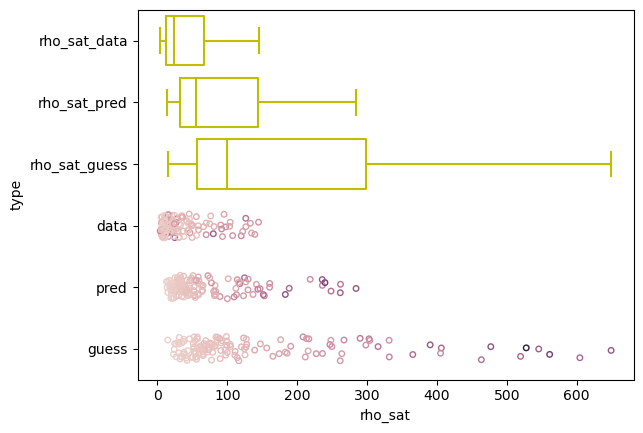

In [174]:
fig9, ax9 = plt.subplots()
ax9 = sns.boxplot(data=rho_sat[['rho_sat_data', 'rho_sat_pred', 'rho_sat_guess']], showfliers = False, orient = 'h', fill = False, color = 'y')
ax9 = sns.stripplot(data=rho_sat_clean, x='rho_sat', y = 'type', marker="$\circ$", jitter = 0.2, hue = 'rho_sat_avg', legend = False)
plt.show()
# fig.savefig('rho_sat_strip.svg')

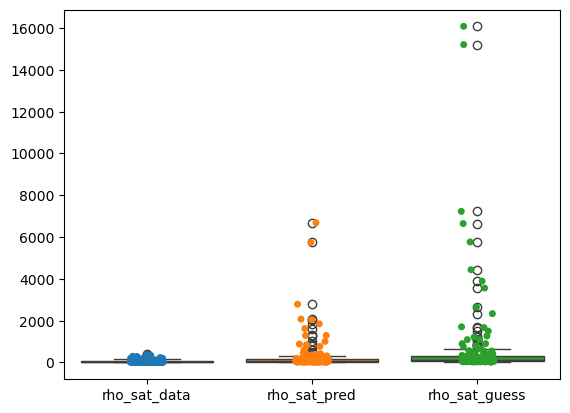

In [164]:
sns.boxplot(data=rho_sat[['rho_sat_data', 'rho_sat_pred', 'rho_sat_guess']])
sns.stripplot(data=rho_sat[['rho_sat_data', 'rho_sat_pred', 'rho_sat_guess']])
plt.show()

In [162]:
rho_sat_clean

,rho_sat,run,type,n,rho_sat_avg
0,11.446391,output_fungi_104,data,104,53.577234
1,34.750042,output_fungi_131,data,131,34.750042
2,5.350350,output_fungi_105,data,105,35.578115
3,5.693407,output_fungi_132,data,132,11.416066
4,14.810769,output_fungi_133,data,133,22.296903
...,...,...,...,...,...
148,59.867231,output_fungi_8,guess,8,37.227906
149,125.339538,output_fungi_92,guess,92,59.121542
150,26.872320,output_fungi_93,guess,93,18.449307
151,263.811656,output_fungi_94,guess,94,139.255526


In [56]:
df = rho_sat
col = 'rho_sat_data'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

# 2. Define acceptable boundaries
lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

# 3. Filter the DataFrame to exclude outliers
clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)]
outliers = df[(df[col] <= lower_bound) | (df[col] >= higher_bound)]
# 4. Get the final length
print(f'apparent median={clean[col].median()} +/- {clean[col].std()}')

df = rho_sat
col = 'rho_sat_pred'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

# 2. Define acceptable boundaries
lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

# 3. Filter the DataFrame to exclude outliers
clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)]
outliers = df[(df[col] <= lower_bound) | (df[col] >= higher_bound)]
# 4. Get the final length
print(f'predicted median={clean[col].median()} +/- {clean[col].std()}')


df = rho_sat
col = 'rho_sat_guess'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

# 2. Define acceptable boundaries
lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

# 3. Filter the DataFrame to exclude outliers
clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)]
outliers = df[(df[col] <= lower_bound) | (df[col] >= higher_bound)]
# 4. Get the final length
print(f'initial guess median={clean[col].median()} +/- {clean[col].std()}')

apparent median=18.503689890568577 +/- 34.50213541704557
predicted median=61.957245817708085 +/- 47.280041915953056
initial guess median=87.4988461746542 +/- 137.14702024520568


In [ ]:
par_cb = par_mn.merge(par_lb, on = 'run', suffixes=('_mn', '_lb'))
par_ub = par_ub.rename(columns={"alpha": "alpha_ub", "beta": "beta_ub","vd": "vd_ub", "sg": "sg_ub", "D": "D_ub"})
par_cb = par_cb.merge(par_ub, on = 'run')

In [ ]:
par_cb['alpha_p'] = (par_cb['alpha_ub'] - par_cb['alpha_mn']) / par_cb['alpha_mn'] 
par_cb['beta_p'] = (par_cb['beta_ub'] - par_cb['beta_mn']) / par_cb['beta_mn'] 
par_cb['vd_p'] = (par_cb['vd_ub'] - par_cb['vd_mn']) / par_cb['vd_mn'] 
par_cb['sg_p'] = (par_cb['sg_ub'] - par_cb['sg_mn']) / par_cb['sg_mn'] 
par_cb['D_p'] = (par_cb['D_ub'] - par_cb['D_mn']) / par_cb['D_mn'] 

par_cb['alpha_m'] = (par_cb['alpha_mn'] - par_cb['alpha_lb']) / par_cb['alpha_mn'] 
par_cb['beta_m'] = (par_cb['beta_mn'] - par_cb['beta_lb']) / par_cb['beta_mn'] 
par_cb['vd_m'] = (par_cb['vd_mn'] - par_cb['vd_lb']) / par_cb['vd_mn'] 
par_cb['sg_m'] = (par_cb['sg_mn'] - par_cb['sg_lb']) / par_cb['sg_mn'] 
par_cb['D_m'] = (par_cb['D_mn'] - par_cb['D_lb']) / par_cb['D_mn']

par_cb['alpha_width'] = (par_cb['alpha_ub'] - par_cb['alpha_lb']) / par_cb['alpha_mn'] 
par_cb['beta_width'] = (par_cb['beta_ub'] - par_cb['beta_lb']) / par_cb['beta_mn'] 
par_cb['vd_width'] = (par_cb['vd_ub'] - par_cb['vd_lb']) / par_cb['vd_mn'] 
par_cb['sg_width'] = (par_cb['sg_ub'] - par_cb['sg_lb']) / par_cb['sg_mn'] 
par_cb['D_width'] = (par_cb['D_ub'] - par_cb['D_lb']) / par_cb['D_mn'] 

In [ ]:
par_cb.boxplot(['alpha_width', 'beta_width', 'vd_width', 'sg_width', 'D_width'], showfliers = False)
plt.savefig('par_width.svg')

In [ ]:
par_cb['D_width'].mean()

In [ ]:
rmse = pd.DataFrame({'run': sim_names, 'rmse_n': rmse_n[:153], 'rmse_rho': rmse_rho[:153], 'rmse_c': rmse_c[:153]})

In [448]:
error = rmse.merge(alpha_r2, on = 'run')
error = error.merge(beta_r2, on = 'run')
error['rmse_total'] = error['rmse_n'] + error['rmse_rho'] + error['rmse_c']

slope:-0.30175937598784375
r-squared:0.14651804474667146
p value:1.1336949088127406e-06
slope:-0.3460021770851521
r-squared:0.16527990547762464
p value:2.0240508645891923e-07


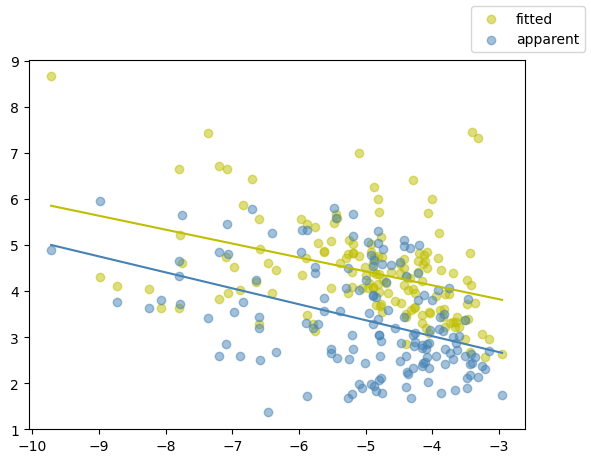

In [43]:
plot1 = par_mn['beta'][:152]
plot2 = rho_sat['rho_sat_pred'][:152]
plot3 = rho_sat['rho_sat_data'][:152]
plot4 = rho_sat['rho_sat_guess'][:152]
fig1, ax1 = plt.subplots()
ax1.scatter(np.log(plot1), np.log(plot2), color = 'y', alpha = 0.5, label = 'fitted')
ax1.scatter(np.log(plot1), np.log(plot3), color = 'steelblue', alpha = 0.5, label = 'apparent')
res = stats.linregress(np.log(plot1), np.log(plot2))
print(f'slope:{res.slope}')
print(f'r-squared:{(res.rvalue) ** 2}')
print(f'p value:{res.pvalue}')
x = np.linspace(np.min(np.log(plot1)), np.max(np.log(plot1)), 100)
ax1.plot(x, (x * res.slope) + res.intercept, color = 'y')

res = stats.linregress(np.log(plot1), np.log(plot3))
print(f'slope:{res.slope}')
print(f'r-squared:{(res.rvalue) ** 2}')
print(f'p value:{res.pvalue}')
x = np.linspace(np.min(np.log(plot1)), np.max(np.log(plot1)), 100)
ax1.plot(x, (x * res.slope) + res.intercept, color = 'steelblue')

fig1.legend()

fig1.savefig('rho_vs_beta.svg')

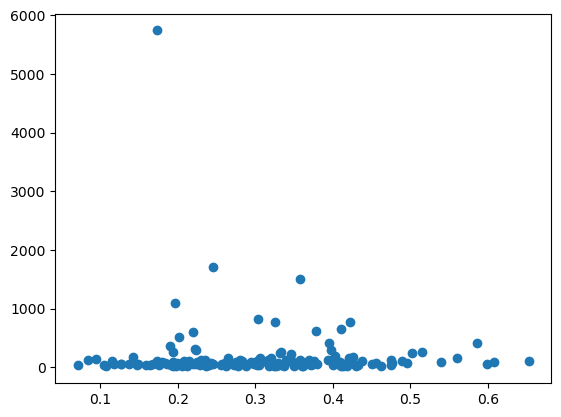

In [1043]:
fig, ax = plt.subplots()
ax.scatter(plot1, plot2)

143
9


<Axes: >

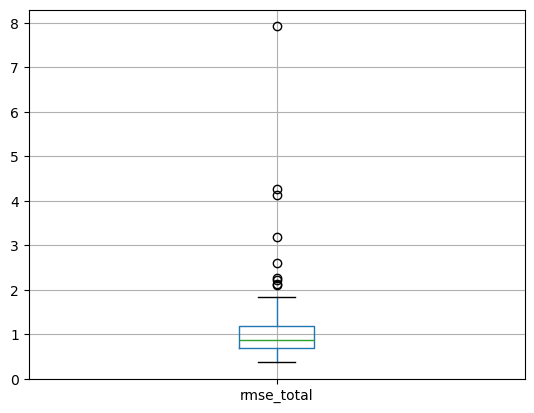

In [521]:
df = error
col = 'rmse_total'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

# 2. Define acceptable boundaries
lower_bound = Q1 - 1.5 * IQR
higher_bound = Q3 + 1.5 * IQR

# 3. Filter the DataFrame to exclude outliers
clean = df[(df[col] >= lower_bound) & (df[col] <= higher_bound)]
outliers = df[(df[col] <= lower_bound) | (df[col] >= higher_bound)]
# 4. Get the final length
print(len(clean))
print(len(outliers))
df.boxplot([col])

In [740]:
error.sort_values(by=["rmse_total"])

,run,rmse_n,rmse_rho,rmse_c,alpha_r2,beta_r2,rmse_total
51,output_fungi_166,0.182306,0.144247,0.038286,0.958928,0.866912,0.364839
36,output_fungi_150,0.104151,0.212016,0.076418,0.974952,0.948700,0.392585
127,output_fungi_59,0.147177,0.216615,0.046090,0.877384,0.878047,0.409883
130,output_fungi_66,0.327793,0.066292,0.032703,0.969497,0.980831,0.426788
63,output_fungi_210,0.064324,0.299891,0.089005,0.987637,0.675882,0.453220
...,...,...,...,...,...,...,...
86,output_fungi_252,0.371692,2.040563,0.192116,0.882114,0.440294,2.604372
128,output_fungi_60,0.416727,2.705846,0.066822,0.967754,0.570204,3.189395
77,output_fungi_222,0.859810,3.179949,0.075652,0.851137,0.408734,4.115411
98,output_fungi_184,0.388051,3.564499,0.311324,0.927225,0.341949,4.263874


In [44]:
sim_name = 'output_fungi_106'
FX_n = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/bmxfungi_AMALGAM/' + sim_name + '_FX', header = None, names = ['n', 'rho', 'c'])
X_n = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/bmxfungi_AMALGAM/' + sim_name + '_X', header = None, names = ['alpha', 'beta', 'vd', 'sg', 'D'])
XZ1_n = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/bmxfungi_AMALGAM/' + sim_name + '_XZ1', header = None, names = ['alpha', 'beta', 'vd', 'sg', 'D'])

In [45]:
FX_n['total'] = FX_n['n'] + FX_n['rho'] + FX_n['c']

In [46]:
FX_norm = FX_n
FX_norm['n'] = FX_norm['n'] / (FX_norm['n'].max() - FX_norm['n'].min())
FX_norm['rho'] = FX_norm['rho'] / (FX_norm['rho'].max() - FX_norm['rho'].min())
FX_norm['c'] = FX_norm['c'] / (FX_norm['c'].max() - FX_norm['c'].min())

In [47]:
F = FX_n

In [48]:
def pareto_obj(best, args):
    z, time = args['z'], args['time']
    
    upar = [z[7], z[8], z[9]]
    upar[2] = 0.1
    
    t0 = z[10]
    shifted_time = time - t0
    
    z_t, z_r = z[0:2]
    y_t, y_r = PDE(best, upar, time, 0)

    t_data = z_t.merge(y_t, on = 't', how = 'inner', suffixes = ('_z', '_y'))
    t_data['n_res'] = abs(t_data['n_z'] - t_data['n_y'])
    t_data['rho_res'] = abs(t_data['rho_z'] - t_data['rho_y'])
    t_data['n_wssr'] = t_data['n_wt'] * (t_data['n_res'] ** 2)
    t_data['rho_wssr'] = t_data['rho_wt'] * (t_data['rho_res'] ** 2)
    t_data['c_res'] = abs(t_data['c_z'] - t_data['c_y'])
    t_data['c_wssr'] = t_data['c_wt'] * (t_data['c_res'] ** 2)

    return [t_data['n_wssr'].sum(), t_data['rho_wssr'].sum(), t_data['c_wssr'].sum()]

In [49]:
mn_n = par_mn_df.loc[sim_name]
z_t = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_tobjectives.csv')
z_r = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_robjectives.csv')
z_const = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/figure_data/' + sim_name + '_constantguess.csv')
z = [z_t, z_r, z_const['alpha'][0], z_const['beta'][0], z_const['vd'][0], z_const['sg'][0], z_const['D'][0], z_const['A'][0], z_const['s'][0], z_const['r0'][0], z_const['t0'][0]]

In [50]:
fig, ax = plt.subplots(3, 1, figsize = (4, 9))
cmap = mpl.cm.Greys(np.linspace(0,1,30))
cm = mpl.colors.ListedColormap(cmap[5:,:-1])

sc1 = ax[0].scatter(F['n'], F['rho'], c = F['c'], cmap = cm, marker = '.')
ax[0].set_xlabel(r'$F_n$')
ax[0].set_ylabel(r'$F_{\rho}$')
sc2 = ax[1].scatter(F['n'], F['c'], c = F['rho'], cmap = cm, marker = '.')
ax[1].set_xlabel(r'$F_n$')
ax[1].set_ylabel(r'$F_c$')
sc3 = ax[2].scatter(F['rho'], F['c'], c = F['n'], cmap = cm, marker = '.')
ax[2].set_xlabel(r'$F_{\rho}$')
ax[2].set_ylabel(r'$F_c$')

ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[2].set_xscale('log')
ax[2].set_yscale('log')

ax[0].scatter(F[F['n'] == F['n'].min()]['n'], F[F['n'] == F['n'].min()]['rho'], color = 'r')
ax[0].scatter(F[F['rho'] == F['rho'].min()]['n'], F[F['rho'] == F['rho'].min()]['rho'], color = 'xkcd:golden yellow')
ax[1].scatter(F[F['n'] == F['n'].min()]['n'], F[F['n'] == F['n'].min()]['c'], color = 'r')
ax[1].scatter(F[F['c'] == F['c'].min()]['n'], F[F['c'] == F['c'].min()]['c'], color = 'tab:blue')
ax[2].scatter(F[F['rho'] == F['rho'].min()]['rho'], F[F['rho'] == F['rho'].min()]['c'], color = 'xkcd:golden yellow')
ax[2].scatter(F[F['c'] == F['c'].min()]['rho'], F[F['c'] == F['c'].min()]['c'], color = 'tab:blue')

ax[0].scatter(F[F['total'] == F['total'].min()]['n'], F[F['total'] == F['total'].min()]['rho'], color = 'y', marker = '*', s = 50)
ax[1].scatter(F[F['total'] == F['total'].min()]['n'], F[F['total'] == F['total'].min()]['c'], color = 'y', marker = '*', s = 50)
ax[2].scatter(F[F['total'] == F['total'].min()]['rho'], F[F['total'] == F['total'].min()]['c'], color = 'y', marker = '*', s = 50)

# ax[0].scatter(F_best[0], F_best[1], color = 'tab:orange', marker = '*', s = 50)
# ax[1].scatter(F_best[0], F_best[2], color = 'tab:orange', marker = '*', s = 50)
# ax[2].scatter(F_best[1], F_best[2], color = 'tab:orange', marker = '*', s = 50)

fig.colorbar(sc1, ax=ax[0], label = 'c')
fig.colorbar(sc2, ax=ax[1], label = 'rho')
fig.colorbar(sc3, ax=ax[2], label = 'n')
plt.tight_layout()

# plt.savefig('pareto_ex.svg')

Form has no parts with arity 2.


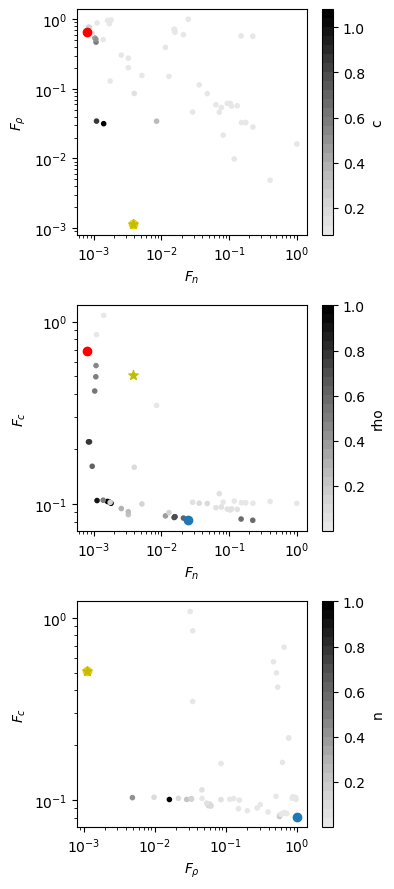

[np.float64(874.2349158439778),
 np.float64(16533.491139110927),
 np.float64(66.62686379859821)]

In [51]:
pareto_obj([X_n.loc[0, 'alpha'],X_n.loc[0, 'beta'], X_n.loc[0, 'vd'], X_n.loc[0, 'sg'], X_n.loc[0, 'D']], {'z': z, 'time': len(z[0])})

In [949]:
F_best = pareto_obj([mn_n['alpha'],mn_n['beta'], mn_n['vd'], mn_n['sg'], mn_n['D']], {'z': z, 'time': len(z[0])})

Form has no parts with arity 2.


In [53]:
rank1_n = FX_n.join(X_n)

Form has no parts with arity 2.


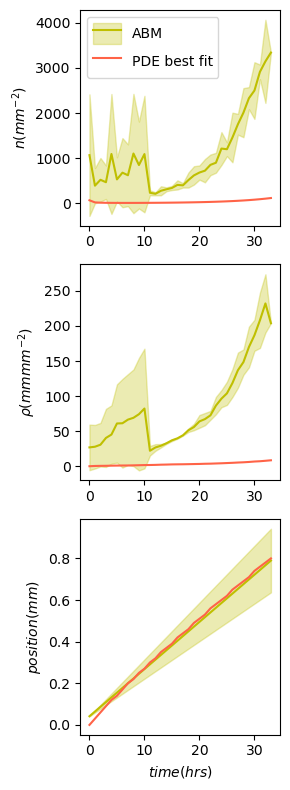

In [56]:
FX_n_best = rank1_n[rank1_n['n'] == rank1_n['n'].min()].to_numpy()
FX_rho_best = rank1_n[rank1_n['rho'] == rank1_n['rho'].min()].to_numpy()
FX_c_best = rank1_n[rank1_n['c'] == rank1_n['c'].min()].to_numpy()
par_n = [FX_n_best[0][4], FX_n_best[0][5], FX_n_best[0][6], FX_n_best[0][7], FX_n_best[0][8]]
par_rho = [FX_rho_best[0][4], FX_rho_best[0][5], FX_rho_best[0][6], FX_rho_best[0][7], FX_rho_best[0][8]]
par_c = [FX_c_best[0][4], FX_c_best[0][5], FX_c_best[0][6], FX_c_best[0][7], FX_c_best[0][8]]
a = plot_residual(par_c, [0,0,0,0,0], [0,0,0,0,0], {'z': z, 'time': len(z[0])})
# a.savefig('n_best_ex.svg')

In [21]:
# Check what's in the RDS file and convert appropriately
r_code = """
obj <- readRDS('/Users/laurenyan/Downloads/all_data.RDS')
print(class(obj))
print(str(obj))
print(length(obj))

# If it's a list, you can save each element or combine them
if(is.list(obj)) {
  # Option 1: Save the first element if it's the main data
  if(is.data.frame(obj[[1]])) {
    write.csv(obj[[1]], '/Users/laurenyan/bmxfungi_surrogate/all_data.csv', row.names=FALSE)
    print("Saved first element")
  } else {
    # Option 2: Convert list to data frame (if appropriate)
    df <- as.data.frame(obj, stringsAsFactors=FALSE)
    write.csv(df, '/Users/laurenyan/bmxfungi_surrogate/all_data.csv', row.names=FALSE)
    print("Saved as combined data frame")
  }
}
"""

result = subprocess.run(['Rscript', '-e', r_code], capture_output=True, text=True)
print(result.stdout)
if result.stderr:
    print("Errors:", result.stderr)

[1] "data.frame"
'data.frame':	72 obs. of  19 variables:
 $ name_col         : chr  "C34(1)_t11" "C34(2)_t23" "C34(3)_t23" "C35(4)_t30" ...
 $ Hyphal_length    : num  1.43 1.39 1.38 1.38 1.87 ...
 $ Hyphal_number    : int  21478 23816 26491 25077 5999 5309 5807 31960 24642 54970 ...
 $ Hyphal_tip_width : num  0.798 0.872 0.872 0.826 0.785 ...
 $ Hyphal_main_width: num  7.27 8.19 8.12 7.93 7.69 ...
 $ Hyphal_tip_access: num  11.4 25.1 Inf 1315 3733.3 ...
 $ Hyphal_angle     : num  73.6 73.2 70.6 70.2 70.7 ...
 $ Mycelia_length   : num  827390 816212 965914 897679 679051 ...
 $ Mycelia_Volume   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ alpha_coeff      : num  0.136 0.15 0.163 0.152 0.153 ...
 $ beta_coeff       : num  1.27 1.3 1.33 1.3 1.31 ...
 $ gamma_coeff      : num  0.424 0.434 0.442 0.435 0.435 ...
 $ Root_eff         : num  0.23 0.408 0.37 0.351 0.302 ...
 $ Reff_tip         : num  0.152 0.214 0.229 0.213 0.103 ...
 $ Geff             : num  0.0912 0.1513 0.143 0.1319 0.0969 ...
 $ Networ

In [176]:
# Read the resulting CSV
df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/all_data.csv')
real_data = df[df['Network'] == 'Real']

In [177]:
real_data

,name_col,Hyphal_length,Hyphal_number,Hyphal_tip_width,Hyphal_main_width,Hyphal_tip_access,Hyphal_angle,Mycelia_length,Mycelia_Volume,alpha_coeff,beta_coeff,gamma_coeff,Root_eff,Reff_tip,Geff,Network,Species,Mycelial_area,Hyphal_density
0,C34(1)_t11,1.433164,21478,0.797765,7.266804,1.141227e+01,73.571899,8.273901e+05,0,0.135715,1.271332,0.423827,0.229856,0.152274,0.091191,Real,Mortierella elongata,29.871790,719.006124
1,C34(2)_t23,1.387206,23816,0.871960,8.185121,2.510958e+01,73.174977,8.162123e+05,0,0.150331,1.300566,0.433569,0.407752,0.213591,0.151341,Real,Mortierella elongata,30.562461,779.256619
2,C34(3)_t23,1.378525,26491,0.871772,8.115372,inf,70.583227,9.659141e+05,0,0.163195,1.326300,0.442144,0.370459,0.229497,0.142997,Real,Mortierella elongata,5.305913,4992.731255
3,C35(4)_t30,1.375656,25077,0.826339,7.931059,1.315006e+03,70.207297,8.976787e+05,0,0.152268,1.304445,0.434860,0.350828,0.213153,0.131931,Real,Umbelopsis isabellina,30.594845,819.647888
4,C41(1)_t25_c,1.871970,5999,0.785097,7.694846,3.733328e+03,70.684636,6.790513e+05,0,0.152896,1.305412,0.435324,0.302291,0.103330,0.096936,Real,Fusarium redolens,59.724397,100.444714
5,C41(2)_t25_c,1.900167,5309,0.787621,7.343224,4.194961e+03,67.369875,7.076345e+05,0,0.151639,1.302856,0.434494,0.247840,0.073157,0.073167,Real,Fusarium redolens,69.973267,75.871833
6,C41(3)_t25_c,1.893747,5807,0.755796,7.190199,6.924564e+03,67.264631,7.309722e+05,0,0.154363,1.308330,0.436305,0.032703,0.010767,0.035878,Real,Fusarium redolens,68.959659,84.208653
7,DF19(1)_t11,1.358634,31960,0.782102,6.946636,1.512726e+01,73.703138,1.043198e+06,0,0.152951,1.305831,0.435312,0.272563,0.101548,0.077664,Real,Mortierella alpina,31.259922,1022.395384
8,DF19(2)_t11,1.339267,24642,0.775232,6.908227,5.224156e+01,74.202748,7.594060e+05,0,0.161468,1.322840,0.440994,0.295195,0.127254,0.086535,Real,Mortierella alpina,20.972517,1174.966251
9,DF19(3)_t11,1.279700,54970,0.714106,6.586537,3.646200e+01,73.623190,1.421892e+06,0,0.167697,1.335350,0.445138,0.191138,0.102198,0.069386,Real,Mortierella alpina,32.270186,1703.429920


In [178]:
micro_data = real_data[(real_data['Species'] == 'Mortierella elongata')|
    (real_data['Species'] == 'Umbelopsis isabellina')|
    (real_data['Species'] == 'Fusarium redolens')|
    (real_data['Species'] == 'Mortierella alpina')|
    (real_data['Species'] == 'Mortierella elongata2')|
    (real_data['Species'] == 'Mucor fragilis')|
    (real_data['Species'] == 'Alternaria sp')|
    (real_data['Species'] == 'Fusarium oxysporum')|
    (real_data['Species'] == 'Mortierella alpina2')]    

In [179]:
micro_data

,name_col,Hyphal_length,Hyphal_number,Hyphal_tip_width,Hyphal_main_width,Hyphal_tip_access,Hyphal_angle,Mycelia_length,Mycelia_Volume,alpha_coeff,beta_coeff,gamma_coeff,Root_eff,Reff_tip,Geff,Network,Species,Mycelial_area,Hyphal_density
0,C34(1)_t11,1.433164,21478,0.797765,7.266804,1.141227e+01,73.571899,8.273901e+05,0,0.135715,1.271332,0.423827,0.229856,0.152274,0.091191,Real,Mortierella elongata,29.871790,719.006124
1,C34(2)_t23,1.387206,23816,0.871960,8.185121,2.510958e+01,73.174977,8.162123e+05,0,0.150331,1.300566,0.433569,0.407752,0.213591,0.151341,Real,Mortierella elongata,30.562461,779.256619
2,C34(3)_t23,1.378525,26491,0.871772,8.115372,inf,70.583227,9.659141e+05,0,0.163195,1.326300,0.442144,0.370459,0.229497,0.142997,Real,Mortierella elongata,5.305913,4992.731255
3,C35(4)_t30,1.375656,25077,0.826339,7.931059,1.315006e+03,70.207297,8.976787e+05,0,0.152268,1.304445,0.434860,0.350828,0.213153,0.131931,Real,Umbelopsis isabellina,30.594845,819.647888
4,C41(1)_t25_c,1.871970,5999,0.785097,7.694846,3.733328e+03,70.684636,6.790513e+05,0,0.152896,1.305412,0.435324,0.302291,0.103330,0.096936,Real,Fusarium redolens,59.724397,100.444714
5,C41(2)_t25_c,1.900167,5309,0.787621,7.343224,4.194961e+03,67.369875,7.076345e+05,0,0.151639,1.302856,0.434494,0.247840,0.073157,0.073167,Real,Fusarium redolens,69.973267,75.871833
6,C41(3)_t25_c,1.893747,5807,0.755796,7.190199,6.924564e+03,67.264631,7.309722e+05,0,0.154363,1.308330,0.436305,0.032703,0.010767,0.035878,Real,Fusarium redolens,68.959659,84.208653
7,DF19(1)_t11,1.358634,31960,0.782102,6.946636,1.512726e+01,73.703138,1.043198e+06,0,0.152951,1.305831,0.435312,0.272563,0.101548,0.077664,Real,Mortierella alpina,31.259922,1022.395384
8,DF19(2)_t11,1.339267,24642,0.775232,6.908227,5.224156e+01,74.202748,7.594060e+05,0,0.161468,1.322840,0.440994,0.295195,0.127254,0.086535,Real,Mortierella alpina,20.972517,1174.966251
9,DF19(3)_t11,1.279700,54970,0.714106,6.586537,3.646200e+01,73.623190,1.421892e+06,0,0.167697,1.335350,0.445138,0.191138,0.102198,0.069386,Real,Mortierella alpina,32.270186,1703.429920


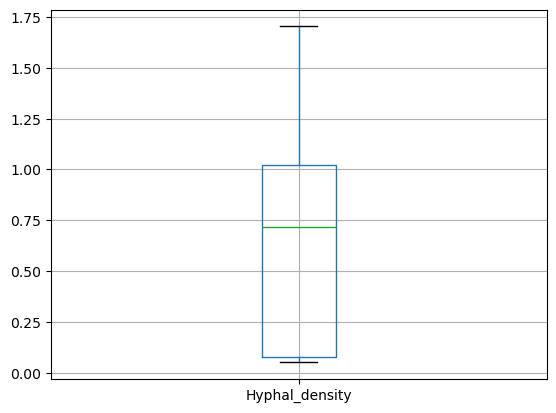

In [118]:
a = micro_data.boxplot(['Hyphal_density'], showfliers = False)

In [106]:
guess_v_mn = par_mn.merge(par_guess, on = 'run', how = 'inner')

In [107]:
guess_v_mn = guess_v_mn.rename(columns ={'alpha': 'alpha_mn', 'beta': 'beta_mn', 'vd': 'vd_mn', 'sg': 'sg_mn', 'D':'D_mn'})

In [108]:
guess_v_mn['alpha_diff'] = (guess_v_mn['alpha_mn'] - guess_v_mn['alpha_guess']) / guess_v_mn['alpha_mn']
guess_v_mn['beta_diff'] = (guess_v_mn['beta_mn'] - guess_v_mn['beta_guess']) / guess_v_mn['beta_mn']
guess_v_mn['vd_diff'] = (guess_v_mn['vd_mn'] - guess_v_mn['vd_guess']) / guess_v_mn['vd_mn']
guess_v_mn['sg_diff'] = (guess_v_mn['sg_mn'] - guess_v_mn['sg_guess']) / guess_v_mn['sg_mn']
guess_v_mn['D_diff'] = (guess_v_mn['D_mn'] - guess_v_mn['D_guess']) / guess_v_mn['D_mn']
guess_v_mn['alpha_diff_abs'] = abs(guess_v_mn['alpha_mn'] - guess_v_mn['alpha_guess']) / guess_v_mn['alpha_mn']
guess_v_mn['beta_diff_abs'] = abs(guess_v_mn['beta_mn'] - guess_v_mn['beta_guess']) / guess_v_mn['beta_mn']
guess_v_mn['vd_diff_abs'] = abs(guess_v_mn['vd_mn'] - guess_v_mn['vd_guess']) / guess_v_mn['vd_mn']
guess_v_mn['sg_diff_abs'] = abs(guess_v_mn['sg_mn'] - guess_v_mn['sg_guess']) / guess_v_mn['sg_mn']
guess_v_mn['D_diff_abs'] = abs(guess_v_mn['D_mn'] - guess_v_mn['D_guess']) / guess_v_mn['D_mn']

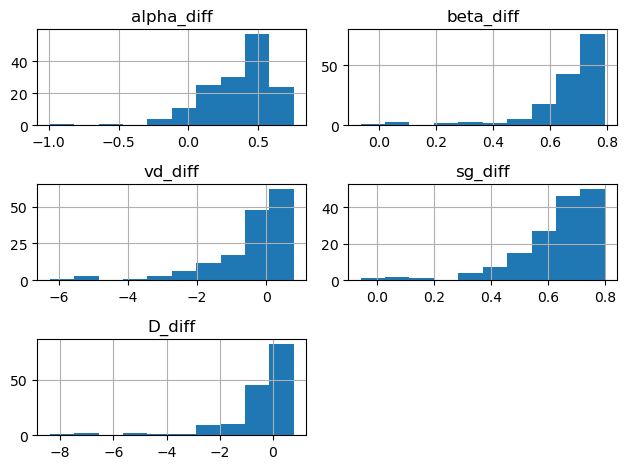

In [112]:
guess_v_mn.hist(['alpha_diff', 'beta_diff', 'vd_diff', 'sg_diff', 'D_diff'])
plt.tight_layout()
plt.savefig('par_accuracy_hist.svg')

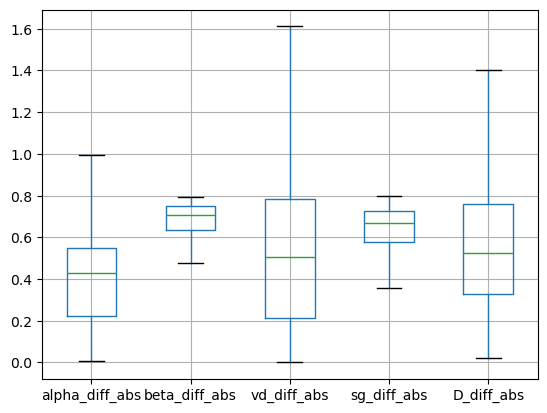

In [111]:
guess_v_mn.boxplot(['alpha_diff_abs', 'beta_diff_abs', 'vd_diff_abs', 'sg_diff_abs', 'D_diff_abs'], showfliers = False)
plt.savefig('par_accuracy_box.svg')